# Spatio-Temporal Kriging of Daily Maximum Temperature

Universal kriging with a Gaussian space-time covariance, applied to NOAA daily maximum temperature (Tmax) at weather stations across the central and eastern United States in July 1993.

The analysis follows five steps:

1. Load the data and explore it.
2. Fit a linear trend by OLS and test its residuals for spatial autocorrelation.
3. Estimate a separable Gaussian space-time covariance function by maximum likelihood.
4. Predict Tmax on a regular space-time grid by universal kriging, with standard errors.
5. Compare against the OLS trend using leave-station-out cross-validation.

Reusable functions (covariance, likelihood, kriging, Moran's I) live in `../src/stkriging.py`.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import pyreadr
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.optimize import minimize

import stkriging as st

FIG_DIR = "../docs/figures"

## 1. Data

### 1.1 Load and filter

The NOAA dataset contains four daily variables (Tmax, Tmin, dew point, precipitation) at stations in the central and eastern US for 1990-1993. We keep Tmax for July 1993 in long format: one row per station-day.

In [2]:
raw = pyreadr.read_r("../data/NOAA_df_1990.rda")["NOAA_df_1990"]
print(f"Full dataset: {raw.shape[0]:,} rows, {raw.shape[1]} columns")
print("Variables:", raw["proc"].unique().tolist())

df_long = raw[(raw["proc"] == "Tmax") & (raw["year"] == 1993) & (raw["month"] == 7)]
df_long = df_long[["id", "lon", "lat", "day", "z"]].reset_index(drop=True)
print(f"\nTmax, July 1993 (long format): {len(df_long):,} rows")
df_long.head()

Full dataset: 729,410 rows, 10 columns
Variables: ['Tmax', 'Tmin', 'TDP', 'Precip']

Tmax, July 1993 (long format): 4,122 rows


,id,lon,lat,day,z
0,3804.0,-81.433334,39.349998,1,82.0
1,3804.0,-81.433334,39.349998,2,84.0
2,3804.0,-81.433334,39.349998,3,88.0
3,3804.0,-81.433334,39.349998,4,90.0
4,3804.0,-81.433334,39.349998,5,92.0


### 1.2 Summary statistics

In [3]:
n_stations = df_long["id"].nunique()
n_days = df_long["day"].nunique()
n_possible = n_stations * n_days
n_missing_z = int(df_long["z"].isna().sum())
n_absent = n_possible - len(df_long)          # station-days with no row at all

print(f"Stations:                      {n_stations}")
print(f"Days:                          {n_days}")
print(f"Possible station-days:         {n_possible:,}")
print(f"Observed (non-missing) values: {df_long['z'].notna().sum():,}")
print(f"Rows with missing z:           {n_missing_z}")
print(f"Absent station-days:           {n_absent}")
print()
print("lon: longitude (degrees, negative = West)   lat: latitude (degrees North)")
print("day: day of July 1993 (1-31)                z:   daily maximum temperature (deg F)")
df_long[["lon", "lat", "day", "z"]].describe().round(2)

Stations:                      133
Days:                          31
Possible station-days:         4,123
Observed (non-missing) values: 4,122
Rows with missing z:           0
Absent station-days:           1

lon: longitude (degrees, negative = West)   lat: latitude (degrees North)
day: day of July 1993 (1-31)                z:   daily maximum temperature (deg F)


,lon,lat,day,z
count,4122.00,4122.00,4122.00,4122.00
mean,-89.04,38.66,16.00,88.55
std,5.72,3.93,8.94,7.75
min,-99.97,32.13,1.00,61.00
25%,-93.77,35.22,8.00,83.00
50%,-88.75,38.82,16.00,89.00
75%,-84.20,41.98,24.00,95.00
max,-80.03,45.87,31.00,106.00


### 1.3 Exploratory plots

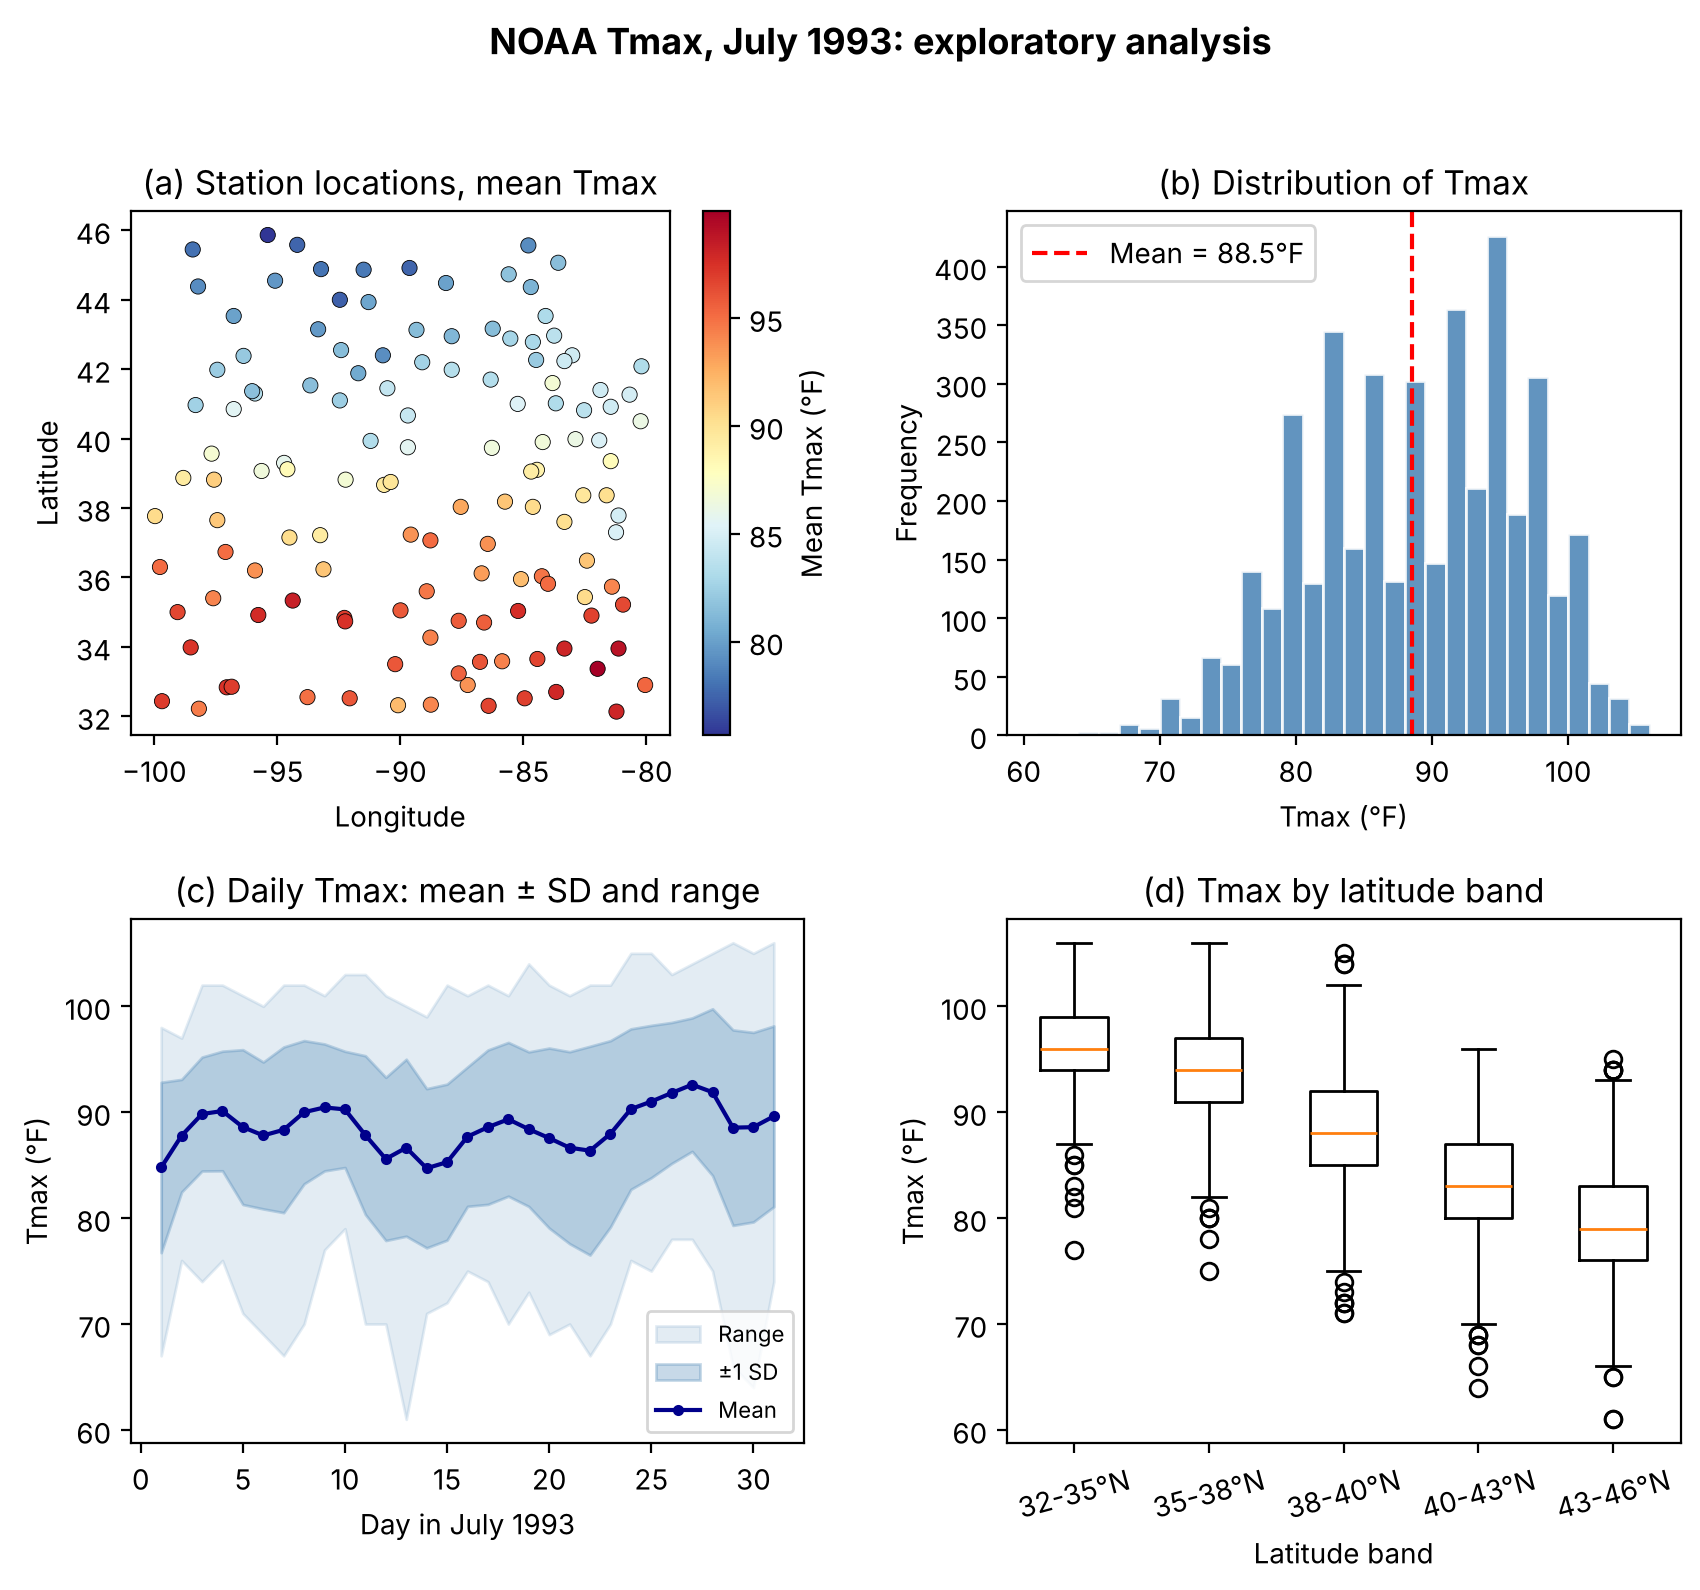

In [4]:
fig = plt.figure(figsize=(10, 8))
gs = GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.3)

# (a) station locations coloured by time-averaged Tmax
ax = fig.add_subplot(gs[0, 0])
stn_mean = df_long.groupby("id").agg(lon=("lon", "first"), lat=("lat", "first"), z=("z", "mean"))
sc = ax.scatter(stn_mean["lon"], stn_mean["lat"], c=stn_mean["z"], cmap="RdYlBu_r",
                s=30, edgecolors="k", linewidths=0.3)
plt.colorbar(sc, ax=ax, label="Mean Tmax (°F)")
ax.set(xlabel="Longitude", ylabel="Latitude", title="(a) Station locations, mean Tmax")

# (b) distribution of Tmax
ax = fig.add_subplot(gs[0, 1])
ax.hist(df_long["z"], bins=30, color="steelblue", edgecolor="white", alpha=0.85)
ax.axvline(df_long["z"].mean(), color="red", linestyle="--",
           label=f"Mean = {df_long['z'].mean():.1f}°F")
ax.set(xlabel="Tmax (°F)", ylabel="Frequency", title="(b) Distribution of Tmax")
ax.legend()

# (c) daily mean, ±1 SD and range across stations
ax = fig.add_subplot(gs[1, 0])
daily = df_long.groupby("day")["z"].agg(["mean", "std", "min", "max"]).reset_index()
ax.fill_between(daily["day"], daily["min"], daily["max"], alpha=0.15, color="steelblue", label="Range")
ax.fill_between(daily["day"], daily["mean"] - daily["std"], daily["mean"] + daily["std"],
                alpha=0.3, color="steelblue", label="±1 SD")
ax.plot(daily["day"], daily["mean"], "o-", color="darkblue", markersize=3, label="Mean")
ax.set(xlabel="Day in July 1993", ylabel="Tmax (°F)", title="(c) Daily Tmax: mean ± SD and range")
ax.legend(fontsize=8)

# (d) Tmax by latitude band
ax = fig.add_subplot(gs[1, 1])
band = pd.cut(df_long["lat"], bins=5, labels=False)
labels = [f"{df_long.loc[band == i, 'lat'].min():.0f}-{df_long.loc[band == i, 'lat'].max():.0f}°N"
          for i in range(5)]
ax.boxplot([df_long.loc[band == i, "z"].values for i in range(5)], tick_labels=labels)
ax.tick_params(axis="x", rotation=15)
ax.set(xlabel="Latitude band", ylabel="Tmax (°F)", title="(d) Tmax by latitude band")

plt.suptitle("NOAA Tmax, July 1993: exploratory analysis", fontsize=13, fontweight="bold", y=1.0)
plt.savefig(f"{FIG_DIR}/eda.png", dpi=150, bbox_inches="tight")
plt.show()

Tmax falls steadily with latitude, and the daily mean moves around substantially from day to day. Both patterns are modelled below.

### 1.4 Working dataset

The missing station-day is dropped, leaving $D = \{(\text{lon}_i, \text{lat}_i, t_i, Z_i)\}_{i=1}^{m}$.

In [5]:
D = df_long.dropna(subset=["z"]).reset_index(drop=True)
m = len(D)

lon_d, lat_d, day_d, Z_d = (D[c].values for c in ["lon", "lat", "day", "z"])
station_ids = D["id"].values
X = st.design_matrix(lon_d, lat_d, day_d)       # columns: 1, lat, lon, day
print(f"m = {m:,} observations at {D['id'].nunique()} stations")

m = 4,122 observations at 133 stations


## 2. Linear trend by OLS

$$Z(s,t) = \beta_0 + \beta_1\,\text{lat} + \beta_2\,\text{lon} + \beta_3\,t + \varepsilon(s,t)$$

OLS assumes independent errors, which is checked next.

In [6]:
beta_ols = np.linalg.solve(X.T @ X, X.T @ Z_d)
fitted_ols = X @ beta_ols
resid_ols = Z_d - fitted_ols

ss_res = np.sum(resid_ols**2)
r2 = 1 - ss_res / np.sum((Z_d - Z_d.mean())**2)
s2 = ss_res / (m - 4)
se_beta = np.sqrt(np.diag(s2 * np.linalg.inv(X.T @ X)))

coef = pd.DataFrame({"Estimate": beta_ols, "Std. error": se_beta, "t-statistic": beta_ols / se_beta},
                    index=["β0 (intercept)", "β1 (lat)", "β2 (lon)", "β3 (day)"])
display(coef.round(4))
print(f"R² = {r2:.4f}    residual SD = {np.sqrt(s2):.3f} °F")
print(f"Latitude effect: {beta_ols[1]:.2f} °F per degree north")
print(f"Temporal trend:  {beta_ols[3]:.4f} °F/day, i.e. {beta_ols[3] * 31:.1f} °F over the month")

,Estimate,Std. error,t-statistic
β0 (intercept),150.5083,1.3337,112.8504
β1 (lat),-1.5581,0.0186,-83.5829
β2 (lon),0.0322,0.0128,2.5184
β3 (day),0.0717,0.0082,8.7642


R² = 0.6328    residual SD = 4.698 °F
Latitude effect: -1.56 °F per degree north
Temporal trend:  0.0717 °F/day, i.e. 2.2 °F over the month


### 2.1 Residual diagnostics

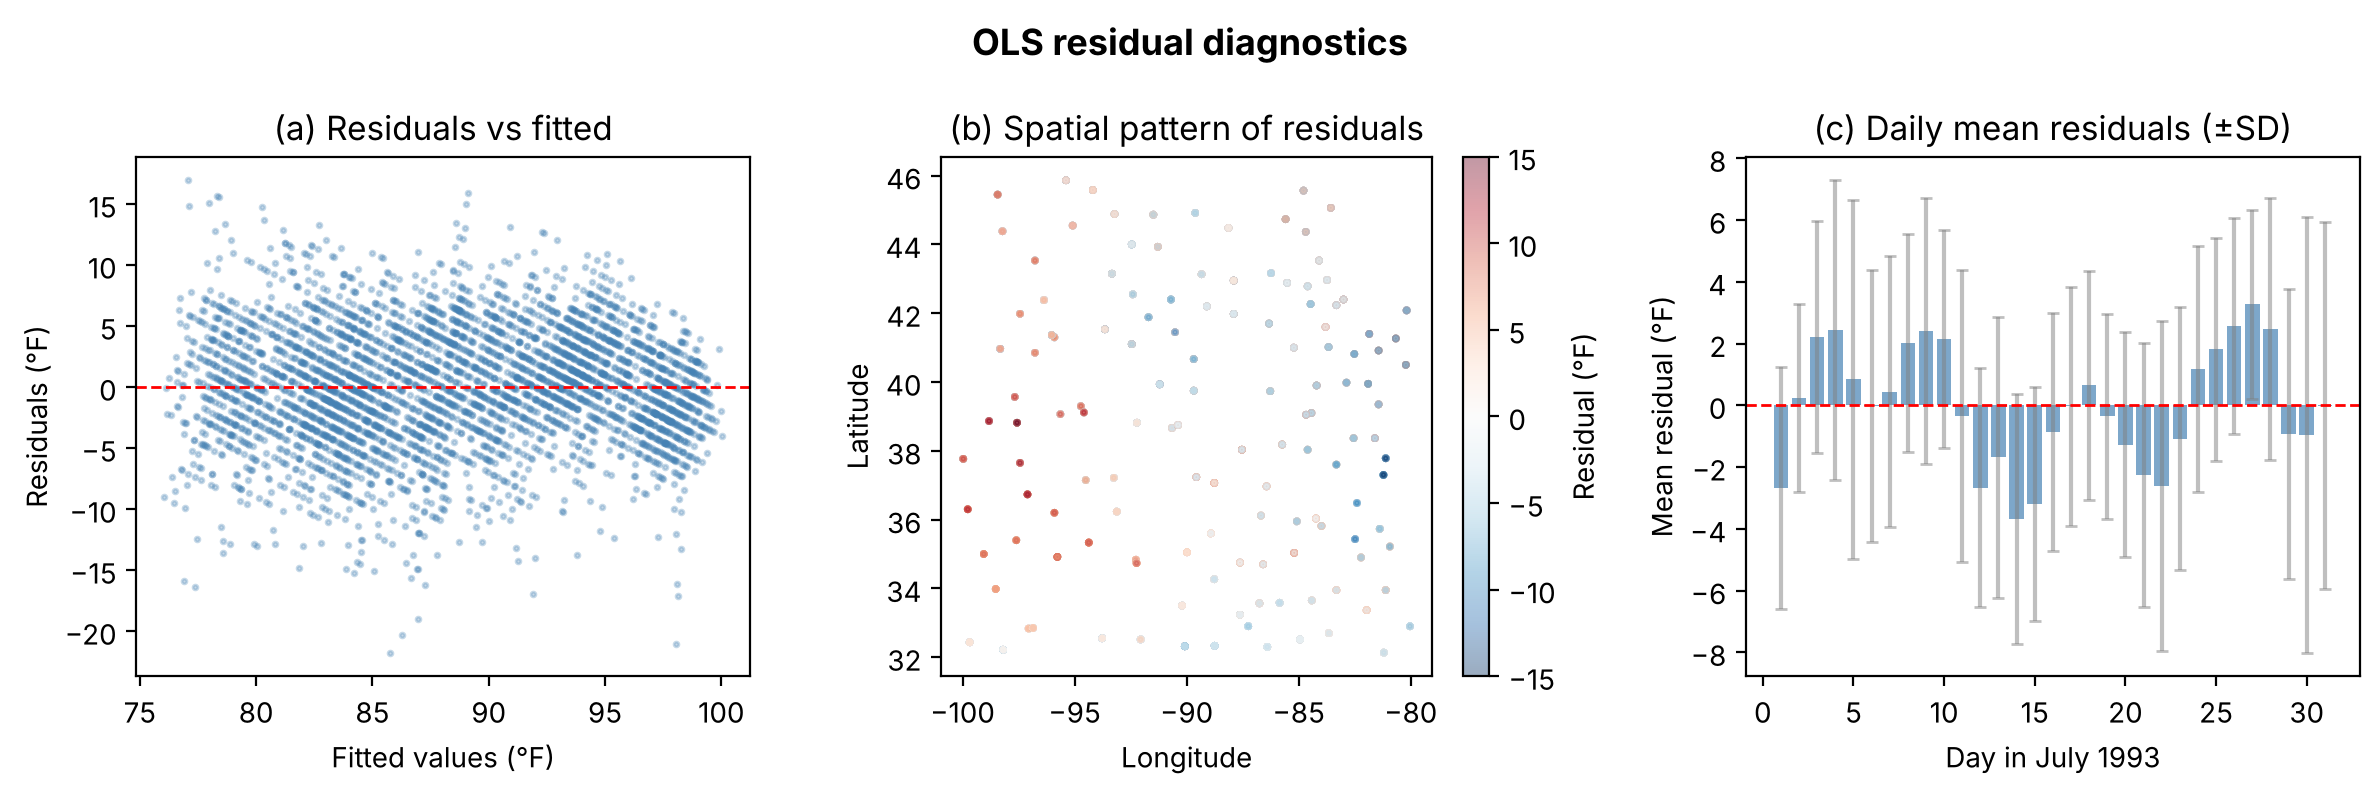

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

ax = axes[0]
ax.scatter(fitted_ols, resid_ols, s=3, alpha=0.3, color="steelblue")
ax.axhline(0, color="red", lw=1, ls="--")
ax.set(xlabel="Fitted values (°F)", ylabel="Residuals (°F)", title="(a) Residuals vs fitted")

ax = axes[1]
sc = ax.scatter(lon_d, lat_d, c=resid_ols, s=3, alpha=0.4, cmap="RdBu_r", vmin=-15, vmax=15)
plt.colorbar(sc, ax=ax, label="Residual (°F)")
ax.set(xlabel="Longitude", ylabel="Latitude", title="(b) Spatial pattern of residuals")

ax = axes[2]
dr = pd.DataFrame({"day": day_d, "r": resid_ols}).groupby("day")["r"].agg(["mean", "std"]).reset_index()
ax.bar(dr["day"], dr["mean"], color="steelblue", alpha=0.7)
ax.errorbar(dr["day"], dr["mean"], yerr=dr["std"], fmt="none", color="grey", alpha=0.5, capsize=2)
ax.axhline(0, color="red", lw=1, ls="--")
ax.set(xlabel="Day in July 1993", ylabel="Mean residual (°F)", title="(c) Daily mean residuals (±SD)")

plt.suptitle("OLS residual diagnostics", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/ols_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.2 Spatial autocorrelation of the residuals (Moran's I)

Moran's I is computed separately for each day (one residual per station, row-standardised inverse-distance weights $w_{ij} = 1/d_{ij}^{p}$). Pooling all days into one calculation is not possible with distance weights, because the same station appears on every day at distance zero. Two values of $p$ are shown since the result depends on how quickly the weights decay.

In [8]:
rows = []
for day, g in D.assign(resid=resid_ols).groupby("day"):
    out = {"day": day}
    for p in (1, 2):
        I, E_I, z, pval = st.morans_i(g["resid"].values, g["lon"].values, g["lat"].values, power=p)
        out[f"I (p={p})"], out[f"p-value (p={p})"] = I, pval
    rows.append(out)
moran = pd.DataFrame(rows).set_index("day")

summary = pd.DataFrame({
    "mean I": [moran["I (p=1)"].mean(), moran["I (p=2)"].mean()],
    "min I": [moran["I (p=1)"].min(), moran["I (p=2)"].min()],
    "max I": [moran["I (p=1)"].max(), moran["I (p=2)"].max()],
    "days with p < 0.05": [(moran["p-value (p=1)"] < 0.05).sum(), (moran["p-value (p=2)"] < 0.05).sum()],
}, index=["weights 1/d", "weights 1/d²"])
display(summary.round(3))
print(f"Expected I under no autocorrelation: about {-1 / (n_stations - 1):.3f}")

,mean I,min I,max I,days with p < 0.05
weights 1/d,0.169,0.068,0.366,31
weights 1/d²,0.419,0.242,0.707,31


Expected I under no autocorrelation: about -0.008


Residuals are positively autocorrelated in space on every day, so the independence assumption behind OLS does not hold. This motivates modelling the error covariance directly.

## 3. Space-time covariance by maximum likelihood

The errors are modelled with a separable Gaussian covariance:

$$C\big((s_i,t_i),(s_j,t_j)\big) = \sigma^2 \exp\!\Big(-\tfrac{\Delta\text{lon}^2}{a^2} - \tfrac{\Delta\text{lat}^2}{b^2} - \tfrac{\Delta t^2}{c^2}\Big) + \tau^2\,\mathbb{1}\{i=j\}$$

| Parameter | Role |
|---|---|
| $\sigma^2$ | variance of the spatially and temporally correlated signal (sill) |
| $a$, $b$ | correlation length-scales in longitude and latitude (degrees) |
| $c$ | correlation length-scale in time (days) |
| $\tau^2$ | nugget: micro-scale variability and measurement noise |

The trend coefficients are profiled out by generalised least squares, so the likelihood is maximised over $(\sigma^2, a, b, c, \tau^2)$ only. A Cholesky factorisation of the full $4{,}122 \times 4{,}122$ covariance is $O(m^3)$ per likelihood evaluation, so the fit uses a random subsample of 800 observations.

In [9]:
N_SUB = 800
np.random.seed(42)
idx_sub = np.sort(np.random.choice(m, size=N_SUB, replace=False))
d2_sub = st.squared_differences(lon_d[idx_sub], lat_d[idx_sub], day_d[idx_sub])

init = np.log([np.var(resid_ols) * 0.8, 5.0, 3.0, 5.0, np.var(resid_ols) * 0.2])
opt = minimize(st.neg_log_likelihood, init, args=(Z_d[idx_sub], X[idx_sub], *d2_sub),
               method="L-BFGS-B", options={"maxiter": 300, "ftol": 1e-8})

theta_hat = np.exp(opt.x)
sigma2_hat, a_hat, b_hat, c_hat, tau2_hat = theta_hat

print(f"Optimiser converged: {opt.success} ({opt.nit} iterations), final negative log-likelihood = {opt.fun:.2f}\n")
pd.DataFrame({"Estimate": theta_hat},
             index=["σ² (signal variance)", "a (lon length-scale, °)", "b (lat length-scale, °)",
                    "c (time length-scale, days)", "τ² (nugget)"]).round(4)

Optimiser converged: True (12 iterations), final negative log-likelihood = 2111.26



,Estimate
σ² (signal variance),15.9767
"a (lon length-scale, °)",5.1309
"b (lat length-scale, °)",3.1241
"c (time length-scale, days)",1.1293
τ² (nugget),4.0435


In [10]:
beta_gls = st.gls_coefficients(Z_d[idx_sub], X[idx_sub], *d2_sub, theta_hat)
print(f"Signal-to-noise ratio σ²/τ² = {sigma2_hat / tau2_hat:.2f}\n")
pd.DataFrame({"OLS": beta_ols, "GLS": beta_gls}, index=["β0", "β1 (lat)", "β2 (lon)", "β3 (day)"]).round(4)

Signal-to-noise ratio σ²/τ² = 3.95



,OLS,GLS
β0,150.5083,146.5832
β1 (lat),-1.5581,-1.4061
β2 (lon),0.0322,0.0543
β3 (day),0.0717,0.0747


### 3.1 Sensitivity to the subsample

The fit is repeated on three further independent subsamples of 800 observations.

In [11]:
names = ["σ²", "a", "b", "c", "τ²"]
fits = {"Main fit (seed 42)": theta_hat}
for seed in (1, 2, 3):
    np.random.seed(seed)
    idx = np.sort(np.random.choice(m, size=N_SUB, replace=False))
    d2 = st.squared_differences(lon_d[idx], lat_d[idx], day_d[idx])
    r = minimize(st.neg_log_likelihood, init, args=(Z_d[idx], X[idx], *d2),
                 method="L-BFGS-B", options={"maxiter": 300, "ftol": 1e-8})
    fits[f"Subsample seed {seed}"] = np.exp(r.x)

sens = pd.DataFrame(fits, index=names).T
display(sens.round(2))
print("Range across the three extra subsamples (relative to the main fit):")
extra = sens.iloc[1:]
print(((extra.max() - extra.min()) / sens.iloc[0] * 100).round(0).astype(int).astype(str).add("%").to_string())

,σ²,a,b,c,τ²
Main fit (seed 42),15.98,5.13,3.12,1.13,4.04
Subsample seed 1,17.39,5.42,3.11,1.33,4.56
Subsample seed 2,19.24,5.86,3.48,1.17,4.98
Subsample seed 3,18.16,6.19,3.81,1.43,5.86


Range across the three extra subsamples (relative to the main fit):
σ²    12%
a     15%
b     23%
c     23%
τ²    32%


The estimates move by roughly 10-30% between subsamples, most for the nugget $\tau^2$ and the length-scales $b$ and $c$. The overall picture is stable, though: spatial correlation extends over roughly 5-6 degrees of longitude and 3-4 degrees of latitude, with weak persistence from day to day (1-1.5 days).

## 4. Prediction grid

A 20 x 20 grid over 100°W-80°W and 32°N-46°N, at six days spread across the month.

In [12]:
lon_grid = np.linspace(-100, -80, 20)
lat_grid = np.linspace(32, 46, 20)
days_grid = np.array([1, 6, 11, 16, 21, 26])

G_lon, G_lat, G_day = (a.ravel() for a in np.meshgrid(lon_grid, lat_grid, days_grid, indexing="ij"))
n_total, n_time = len(G_lon), len(days_grid)
print(f"{len(lon_grid)} x {len(lat_grid)} = {len(lon_grid) * len(lat_grid)} spatial locations x {n_time} days = {n_total:,} predictions")

20 x 20 = 400 spatial locations x 6 days = 2,400 predictions


## 5. Universal kriging

For a new location $(s_0, t_0)$ the best linear unbiased predictor is

$$\hat Z(s_0,t_0) = x_0^\top \hat\beta_{GLS} + c_0^\top C^{-1}\big(Z - X\hat\beta_{GLS}\big),$$

with kriging variance

$$\mathrm{Var}\big[Z_0 - \hat Z_0\big] = C(s_0,s_0) - c_0^\top C^{-1} c_0 + d_0^\top (X^\top C^{-1} X)^{-1} d_0, \qquad d_0 = x_0 - X^\top C^{-1} c_0 .$$

Each prediction uses the $k = 200$ nearest observations, with distance measured in units of the fitted length-scales $(a, b, c)$. Beyond about two length-scales the Gaussian covariance is below $e^{-4} \approx 2\%$, so more distant points contribute little. This is checked below against $k = 400$.

In [13]:
K = 200
out = np.array([st.krige_point(G_lon[j], G_lat[j], G_day[j], lon_d, lat_d, day_d, Z_d, X,
                               theta_hat, k=K, beta_fallback=beta_ols) for j in range(n_total)])
Z_krig, V_krig = out[:, 0], out[:, 1]
SE_krig = np.sqrt(np.maximum(V_krig, 0))

print(f"Predicted Tmax: {Z_krig.min():.1f} to {Z_krig.max():.1f} °F (mean {Z_krig.mean():.1f})")
print(f"Kriging SE:     {SE_krig.min():.2f} to {SE_krig.max():.2f} °F (mean {SE_krig.mean():.2f})")

Predicted Tmax: 68.4 to 102.2 °F (mean 87.3)
Kriging SE:     0.67 to 3.89 °F (mean 1.11)


### 5.1 Effect of the neighbourhood size (k = 200 vs k = 400)

In [14]:
np.random.seed(99)
check = np.random.choice(n_total, size=50, replace=False)
big = np.array([st.krige_point(G_lon[j], G_lat[j], G_day[j], lon_d, lat_d, day_d, Z_d, X,
                               theta_hat, k=400, beta_fallback=beta_ols) for j in check])

print(f"50 random grid points, k = 200 vs k = 400:")
print(f"  mean |difference in prediction| = {np.mean(np.abs(Z_krig[check] - big[:, 0])):.3f} °F")
print(f"  mean |difference in SE|         = {np.mean(np.abs(SE_krig[check] - np.sqrt(np.maximum(big[:, 1], 0)))):.3f} °F")

50 random grid points, k = 200 vs k = 400:
  mean |difference in prediction| = 0.075 °F
  mean |difference in SE|         = 0.004 °F


### 5.2 Prediction and standard-error maps

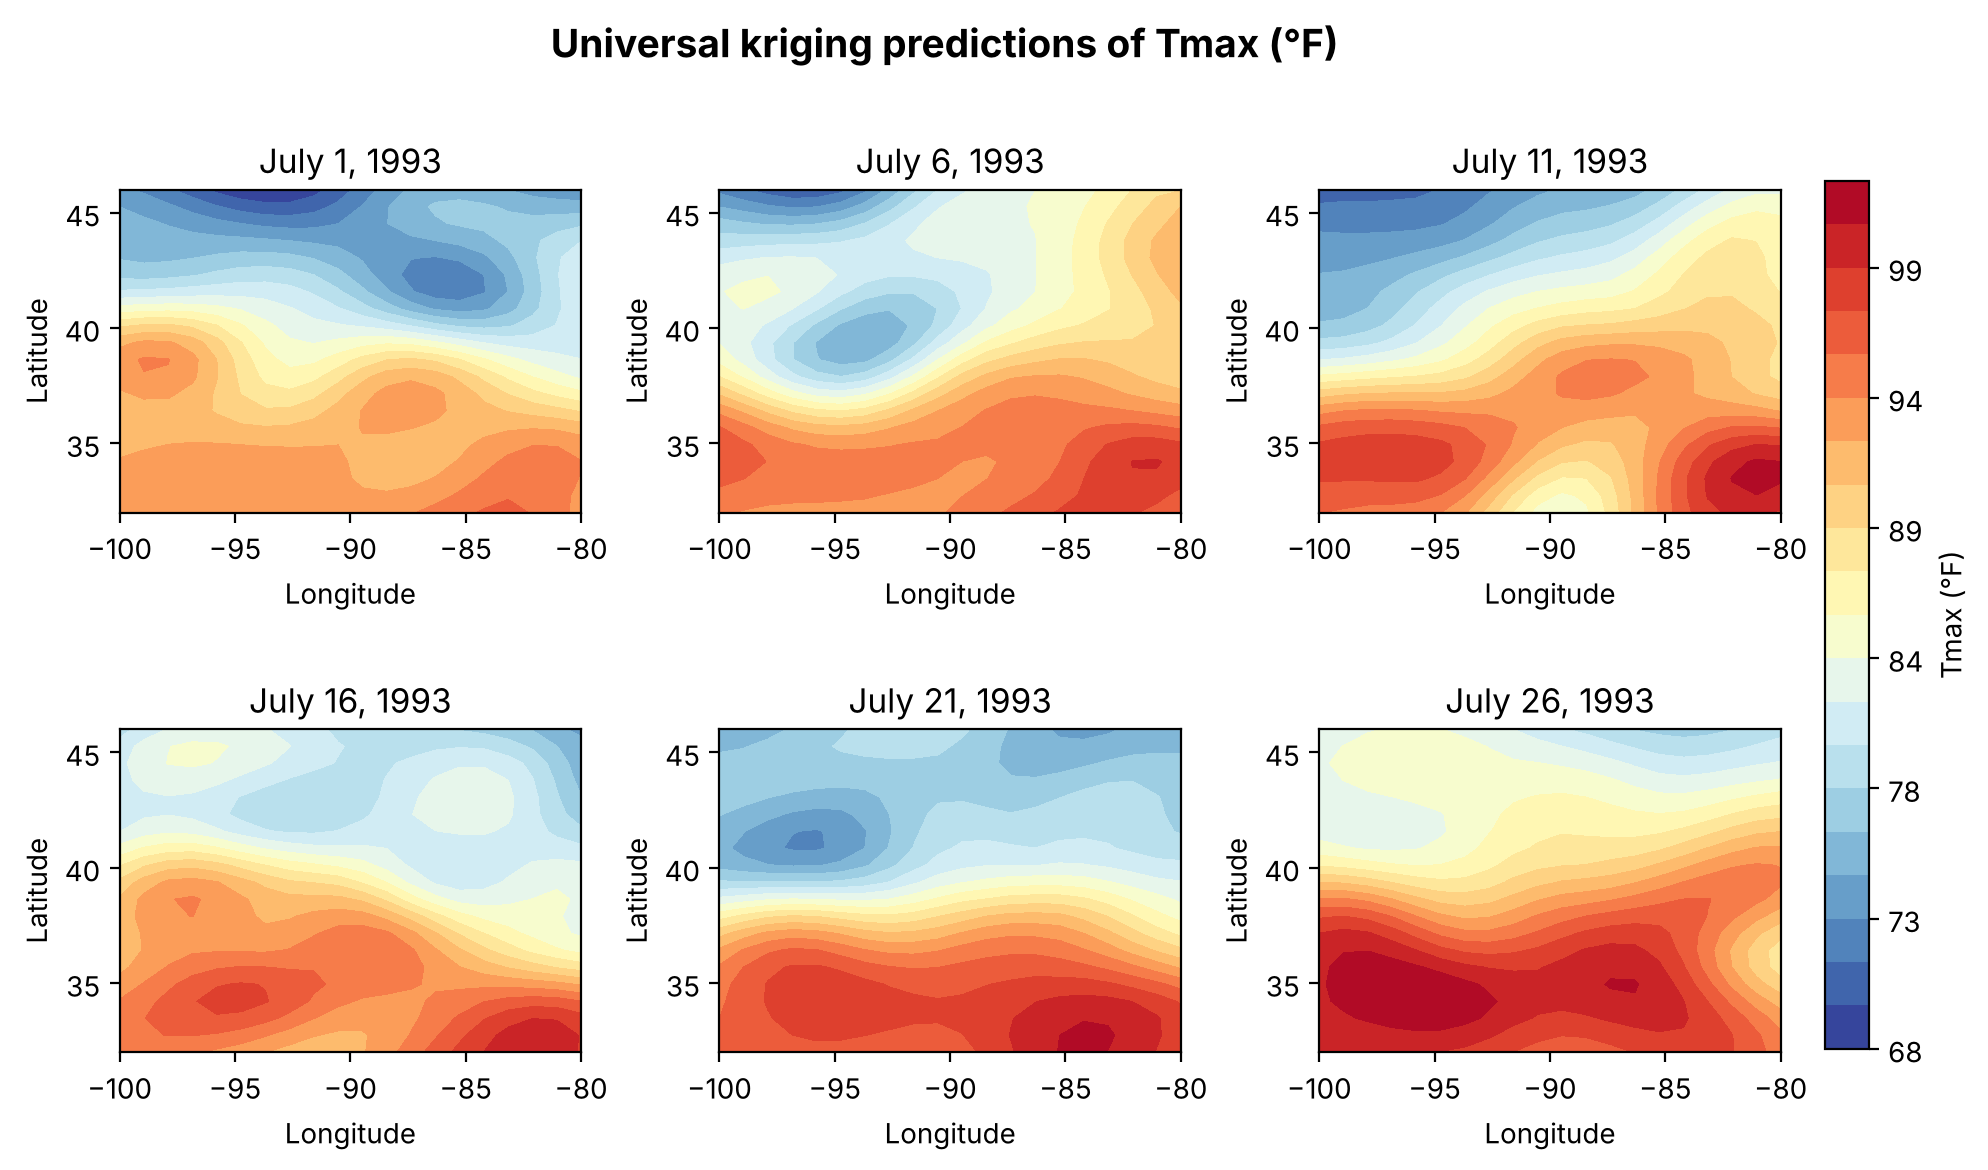

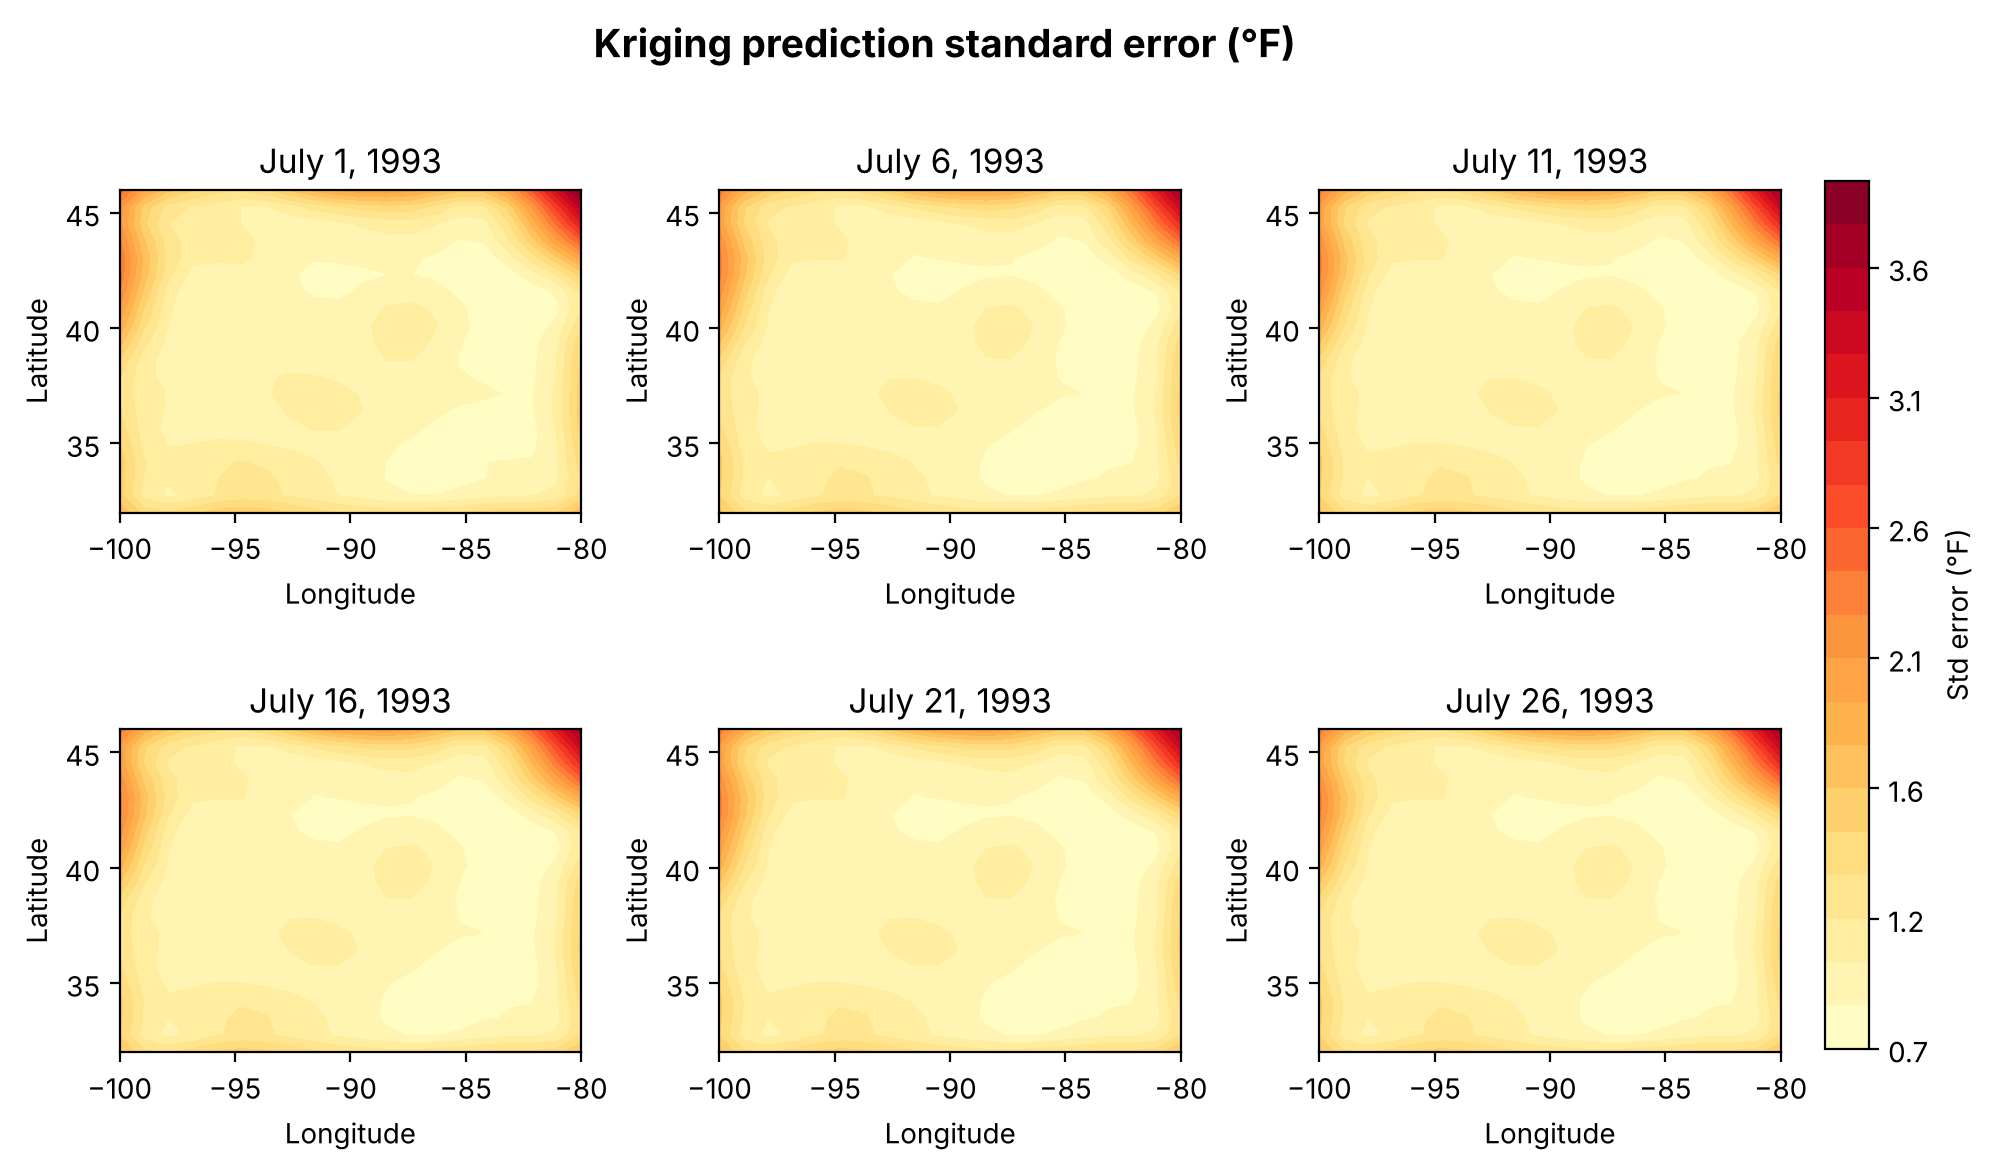

,min,mean,max,SE min,SE max
July 1,68.36,84.55,95.78,0.68,3.89
July 6,70.23,87.33,98.91,0.67,3.67
July 11,70.99,87.01,101.11,0.67,3.67
July 16,74.71,87.40,100.07,0.67,3.67
July 21,73.22,86.13,100.77,0.67,3.67
July 26,77.82,91.12,102.15,0.67,3.67


In [15]:
Z_map = Z_krig.reshape(20, 20, n_time)
SE_map = SE_krig.reshape(20, 20, n_time)
LON, LAT = np.meshgrid(lon_grid, lat_grid, indexing="ij")

def six_panel(field, cmap, vmin, vmax, title, cbar_label, path, fmt="%.0f"):
    levels = np.linspace(vmin - 1e-6, vmax + 1e-6, 21)      # common levels so one colorbar fits every panel
    fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))
    for i, d in enumerate(days_grid):
        ax = axes[i // 3, i % 3]
        cf = ax.contourf(LON, LAT, field[:, :, i], levels=levels, cmap=cmap)
        ax.set(title=f"July {d}, 1993", xlabel="Longitude", ylabel="Latitude")
        ax.set_aspect("equal")
    fig.suptitle(title, fontsize=14, fontweight="bold")
    fig.subplots_adjust(right=0.88, hspace=0.3, wspace=0.3)
    fig.colorbar(cf, cax=fig.add_axes([0.90, 0.15, 0.02, 0.7]), label=cbar_label, format=fmt)
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

six_panel(Z_map, "RdYlBu_r", Z_krig.min(), Z_krig.max(),
          "Universal kriging predictions of Tmax (°F)", "Tmax (°F)", f"{FIG_DIR}/kriging_predictions.png")
six_panel(SE_map, "YlOrRd", SE_krig.min(), SE_krig.max(),
          "Kriging prediction standard error (°F)", "Std error (°F)", f"{FIG_DIR}/kriging_std_errors.png", fmt="%.1f")

pd.DataFrame({"min": Z_map.min(axis=(0, 1)), "mean": Z_map.mean(axis=(0, 1)), "max": Z_map.max(axis=(0, 1)),
              "SE min": SE_map.min(axis=(0, 1)), "SE max": SE_map.max(axis=(0, 1))},
             index=[f"July {d}" for d in days_grid]).round(2)

Standard errors are smallest where stations are dense and largest at the edges of the domain, beyond the station network. They look nearly identical from day to day because the kriging variance depends on the geometry of the stations, not on the observed values.

## 6. Comparison with the OLS trend

Kriging minus OLS on the grid: -14.7 to 12.5 °F (SD 3.93)


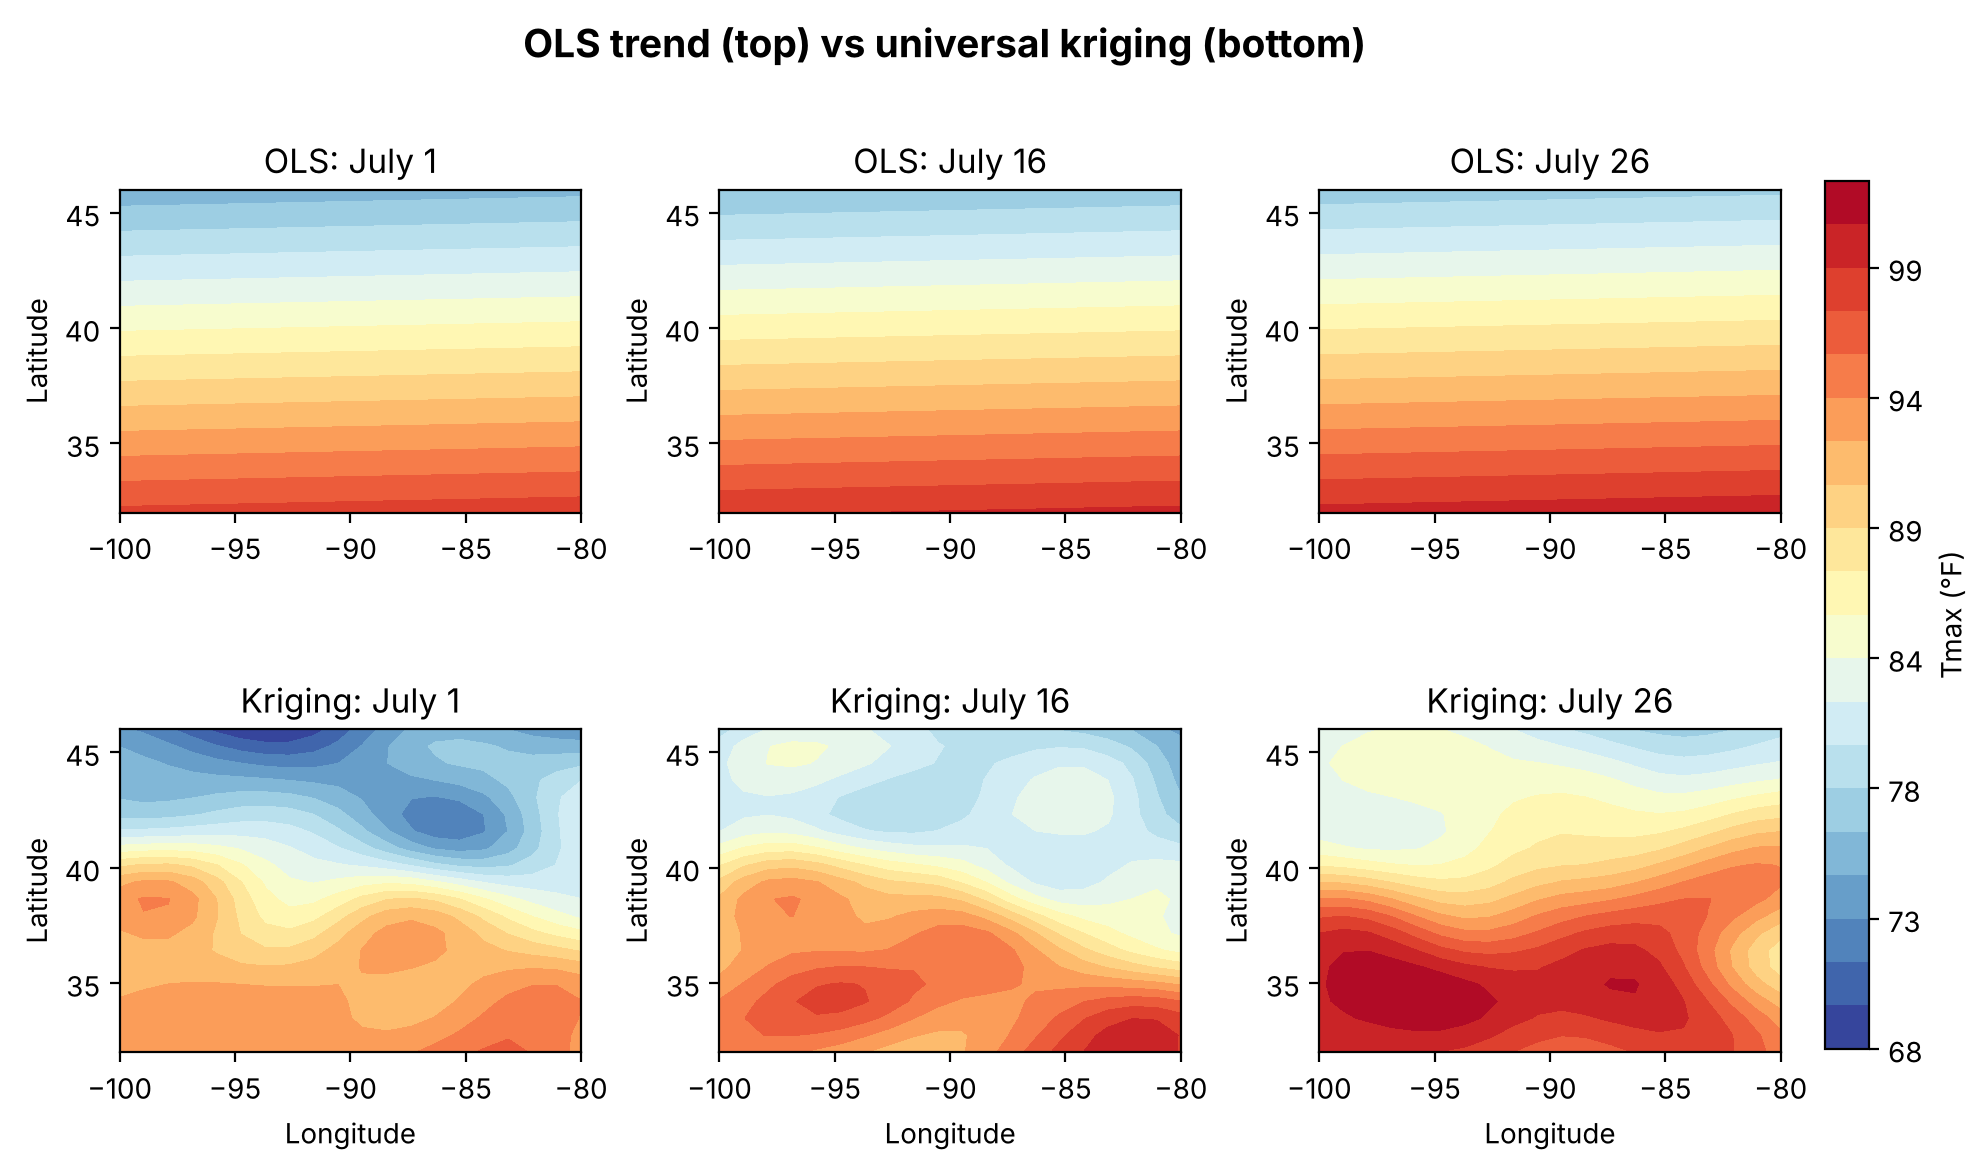

In [16]:
X_grid = st.design_matrix(G_lon, G_lat, G_day)
Z_ols_grid = X_grid @ beta_ols
Z_ols_map = Z_ols_grid.reshape(20, 20, n_time)
diff = Z_krig - Z_ols_grid
print(f"Kriging minus OLS on the grid: {diff.min():.1f} to {diff.max():.1f} °F (SD {diff.std():.2f})")

vmin = min(Z_ols_grid.min(), Z_krig.min())
vmax = max(Z_ols_grid.max(), Z_krig.max())
levels = np.linspace(vmin - 1e-6, vmax + 1e-6, 21)
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))
for col, i in enumerate([0, 3, 5]):
    d = days_grid[i]
    axes[0, col].contourf(LON, LAT, Z_ols_map[:, :, i], levels=levels, cmap="RdYlBu_r")
    axes[0, col].set(title=f"OLS: July {d}", ylabel="Latitude")
    cf = axes[1, col].contourf(LON, LAT, Z_map[:, :, i], levels=levels, cmap="RdYlBu_r")
    axes[1, col].set(title=f"Kriging: July {d}", xlabel="Longitude", ylabel="Latitude")
    for r in (0, 1):
        axes[r, col].set_aspect("equal")
fig.suptitle("OLS trend (top) vs universal kriging (bottom)", fontsize=14, fontweight="bold")
fig.subplots_adjust(right=0.88, hspace=0.3, wspace=0.3)
fig.colorbar(cf, cax=fig.add_axes([0.90, 0.15, 0.02, 0.7]), label="Tmax (°F)", format="%.0f")
plt.savefig(f"{FIG_DIR}/ols_vs_kriging.png", dpi=150, bbox_inches="tight")
plt.show()

The OLS surfaces are smooth planes that barely change between days. Kriging follows the observed weather: local warm and cool areas that differ from day to day.

### 6.1 Leave-station-out cross-validation

Twenty stations (15% of the network, 620 observations) are held out in turn. For each held-out station, OLS is refitted without it and kriging uses only the remaining stations. The covariance parameters are the ones fitted above and are not re-estimated within each fold, which makes the kriging scores slightly optimistic.

In [17]:
def leave_station_out(seed, n_out=20):
    """Hold out n_out random stations in turn; return held-out values, OLS and kriging predictions, kriging variances."""
    np.random.seed(seed)
    held_out = np.random.choice(np.unique(station_ids), size=n_out, replace=False)
    rows = []
    for s in held_out:
        te = np.where(station_ids == s)[0]
        tr = np.where(station_ids != s)[0]
        b_tr = np.linalg.solve(X[tr].T @ X[tr], X[tr].T @ Z_d[tr])
        for j in te:
            p, v = st.krige_point(lon_d[j], lat_d[j], day_d[j], lon_d[tr], lat_d[tr], day_d[tr],
                                  Z_d[tr], X[tr], theta_hat, k=K, beta_fallback=b_tr)
            rows.append((Z_d[j], X[j] @ b_tr, p, v))
    return held_out, np.array(rows).T

def scores(z, pred):
    e = z - pred
    return np.sqrt(np.mean(e**2)), np.mean(np.abs(e))

test_stations, (z_true, z_ols, z_krig, v_krig) = leave_station_out(seed=123)
rmse_o, mae_o = scores(z_true, z_ols)
rmse_k, mae_k = scores(z_true, z_krig)
cv = pd.DataFrame({"OLS": [rmse_o, mae_o], "Kriging": [rmse_k, mae_k],
                   "Improvement": [f"{(1 - rmse_k / rmse_o) * 100:.0f}%", f"{(1 - mae_k / mae_o) * 100:.0f}%"]},
                  index=["RMSE (°F)", "MAE (°F)"])
print(f"{len(z_true)} held-out observations from {len(test_stations)} stations")
cv.round(2)

620 held-out observations from 20 stations


,OLS,Kriging,Improvement
RMSE (°F),4.58,2.37,48%
MAE (°F),3.64,1.84,50%


Scores depend on which stations are held out. The same procedure is repeated for three further random sets of 20 stations:

In [18]:
rows = []
for seed in (123, 7, 8, 9):
    _, (zt, zo, zk, vk) = leave_station_out(seed)
    ro, mo = scores(zt, zo)
    rk, mk = scores(zt, zk)
    cover = np.mean(np.abs(zt - zk) <= 1.96 * np.sqrt(np.maximum(vk, 0) + tau2_hat))
    rows.append({"station set (seed)": seed, "RMSE OLS": ro, "RMSE kriging": rk,
                 "RMSE improvement": f"{(1 - rk / ro) * 100:.0f}%", "MAE OLS": mo, "MAE kriging": mk,
                 "95% coverage (incl. nugget)": f"{cover * 100:.1f}%"})
pd.DataFrame(rows).set_index("station set (seed)").round(2)

,RMSE OLS,RMSE kriging,RMSE improvement,MAE OLS,MAE kriging,95% coverage (incl. nugget)
station set (seed),,,,,,
123,4.58,2.37,48%,3.64,1.84,93.2%
7,4.88,2.08,57%,3.86,1.64,96.3%
8,4.78,2.18,54%,3.77,1.70,96.0%
9,4.76,2.73,43%,3.78,2.14,90.0%


### 6.2 Calibration of the prediction intervals

The kriging variance describes uncertainty about the underlying temperature *field*. A new station-day *observation* also contains the nugget noise $\tau^2$, so an interval meant to cover held-out observations should use $\mathrm{Var}_{krig} + \tau^2$. Both versions are checked against the 95% nominal level.

In [19]:
abs_err = np.abs(z_true - z_krig)
cover_field = np.mean(abs_err <= 1.96 * np.sqrt(np.maximum(v_krig, 0)))
cover_obs = np.mean(abs_err <= 1.96 * np.sqrt(np.maximum(v_krig, 0) + tau2_hat))

pd.DataFrame({"Empirical coverage of ±1.96 SE": [f"{cover_field * 100:.1f}%", f"{cover_obs * 100:.1f}%"]},
             index=["Kriging SE (latent field)", "Kriging SE + nugget (new observation)"])

,Empirical coverage of ±1.96 SE
Kriging SE (latent field),60.0%
Kriging SE + nugget (new observation),93.2%


Intervals for a new observation (including the nugget) are close to the nominal 95%. Using the kriging SE alone, which excludes measurement noise, covers far fewer held-out observations, as expected.

## 7. Limitations and possible extensions

- **Subsample likelihood.** Covariance parameters come from 800 of 4,122 observations. The sensitivity check above shows the estimates vary by roughly 10-30% between subsamples (most for $\tau^2$); Vecchia-type approximations would allow fitting on the full data.
- **Covariance form.** The separable Gaussian model is stationary and axis-aligned. It cannot represent moving weather fronts or spatially varying length-scales. A Matérn family would give control over smoothness.
- **Trend.** A linear trend in lat, lon and day is rigid; polynomial or spline terms may help.
- **Cross-validation.** Twenty held-out stations is a small share of the network, and the covariance parameters are not re-estimated within folds. A full leave-one-station-out scheme with refitting would be a more demanding test.
- **Edges.** Predictions beyond the station network carry the largest uncertainty (see the standard-error maps).